In [2]:
from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [3]:
# Giải nén file ZIP
import zipfile
import os

zip_path = "/content/drive/MyDrive/datasets/Processed_Jester_Dataset.zip"
extract_dir = "/content/Processed_Jester_Dataset"
if not os.path.exists(extract_dir):
    with zipfile.ZipFile(zip_path, 'r') as zip_ref:
        zip_ref.extractall(extract_dir)
    print("Đã giải nén file ZIP!")
else:
    print("Thư mục đã tồn tại, bỏ qua giải nén!")

Đã giải nén file ZIP!


In [4]:
# Cài đặt thư viện
!pip install tensorflow opencv-python numpy pandas scikit-learn seaborn matplotlib

In [5]:
import os
import cv2
import numpy as np
import pandas as pd
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.utils import Sequence, to_categorical


In [6]:
import os

# Kiểm tra tất cả các file trong thư mục
print("Danh sách file trong thư mục giải nén:")
print(os.listdir(extract_dir))


Danh sách file trong thư mục giải nén:
['New_Test.csv', 'New_Test', 'New_Train', 'New_Train.csv', 'New_Validation', 'New_Validation.csv']


In [7]:
import pandas as pd
import os

# Đường dẫn
data_dir = extract_dir
train_csv = os.path.join(data_dir, "New_Train.csv")
val_csv = os.path.join(data_dir, "New_Validation.csv")
test_csv = os.path.join(data_dir, "New_Test.csv")
train_path = os.path.join(data_dir, "New_Train")
val_path = os.path.join(data_dir, "New_Validation")
test_path = os.path.join(data_dir, "New_Test")

# Thông số
WIDTH = 100
HEIGHT = 100
TARGET_SIZE = (HEIGHT, WIDTH)
BATCH_SIZE = 32
N_FRAMES = 37
N_CLASSES = 6
EPOCHS = 20




In [8]:
# Đọc dữ liệu từ CSV
train_df = pd.read_csv(train_csv)
val_df = pd.read_csv(val_csv)
test_df = pd.read_csv(test_csv)

print("Dữ liệu đã được chuẩn bị!")
print(f"Số mẫu train: {len(train_df)}, validation: {len(val_df)}, test: {len(test_df)}")


Dữ liệu đã được chuẩn bị!
Số mẫu train: 9912, validation: 1239, test: 1239


In [9]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.utils import Sequence, to_categorical
# Generator tùy chỉnh để tải dữ liệu video
class VideoDataGenerator(Sequence):
    def __init__(self, dataframe, directory, batch_size, target_size, n_frames, shuffle=True, class_mode='categorical'):
        self.dataframe = dataframe
        self.directory = directory
        self.batch_size = batch_size
        self.target_size = target_size
        self.n_frames = n_frames
        self.shuffle = shuffle
        self.class_mode = class_mode
        self.indexes = np.arange(len(self.dataframe))
        self.label_map = {label: idx for idx, label in enumerate(sorted(self.dataframe['label'].unique()))}
        self.on_epoch_end()

    def __len__(self):
        return int(np.floor(len(self.dataframe) / self.batch_size))

    def __getitem__(self, index):
        indexes = self.indexes[index * self.batch_size:(index + 1) * self.batch_size]
        X, y = [], []
        for idx in indexes:
            video_id = str(self.dataframe.iloc[idx]['video_id'])
            label = self.dataframe.iloc[idx]['label']
            video_path = os.path.join(self.directory, video_id)

            # Tải 37 frame
            frames = []
            for frame_file in sorted(os.listdir(video_path))[:self.n_frames]:
                frame_path = os.path.join(video_path, frame_file)
                frame = cv2.imread(frame_path, cv2.IMREAD_GRAYSCALE)
                frame = cv2.resize(frame, self.target_size)
                frames.append(frame)
            while len(frames) < self.n_frames:
                frames.append(frames[-1])

            X.append(np.array(frames))
            y.append(self.label_map[label])

        X = np.array(X) / 255.0
        X = X.reshape((X.shape[0], self.n_frames, self.target_size[0], self.target_size[1], 1))
        y = np.array(y)

        if self.class_mode == 'categorical':
            y = to_categorical(y, num_classes=len(self.label_map))

        return X, y

    def on_epoch_end(self):
        if self.shuffle:
            np.random.shuffle(self.indexes)


In [10]:
# Tạo generator
train_generator = VideoDataGenerator(
    dataframe=train_df,
    directory=train_path,
    batch_size=BATCH_SIZE,
    target_size=TARGET_SIZE,
    n_frames=N_FRAMES,
    shuffle=True,
    class_mode='categorical'
)

val_generator = VideoDataGenerator(
    dataframe=val_df,
    directory=val_path,
    batch_size=BATCH_SIZE,
    target_size=TARGET_SIZE,
    n_frames=N_FRAMES,
    shuffle=False,
    class_mode='categorical'
)

test_generator = VideoDataGenerator(
    dataframe=test_df,
    directory=test_path,
    batch_size=BATCH_SIZE,
    target_size=TARGET_SIZE,
    n_frames=N_FRAMES,
    shuffle=False,
    class_mode='categorical'
)

# Lưu ánh xạ nhãn
label_map = train_generator.label_map
print("Ánh xạ nhãn:", label_map)
print("Generator đã được tạo!")


Ánh xạ nhãn: {'No gesture': 0, 'Shaking Hand': 1, 'Swiping Up': 2, 'Thumb Down': 3, 'Thumb Up': 4, 'Zooming Out With Two Fingers': 5}
Generator đã được tạo!


In [11]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv3D, MaxPooling3D, Dense, Dropout, Flatten
from tensorflow.keras.layers import BatchNormalization, SimpleRNN, TimeDistributed
from tensorflow.keras.regularizers import l2
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

In [16]:
# Xây dựng mô hình 3D CNN + RNN
model_3dcnn_rnn = Sequential([
    # Các lớp 3D CNN
    Conv3D(32, kernel_size=(3, 3, 3), activation='relu', padding='same',
           input_shape=(N_FRAMES, HEIGHT, WIDTH, 1), kernel_regularizer=l2(0.001)),
    BatchNormalization(),
    MaxPooling3D(pool_size=(2, 2, 2)),

    Conv3D(64, kernel_size=(3, 3, 3), activation='relu', padding='same', kernel_regularizer=l2(0.001)),
    BatchNormalization(),
    MaxPooling3D(pool_size=(2, 2, 2)),

    Conv3D(128, kernel_size=(3, 3, 3), activation='relu', padding='same', kernel_regularizer=l2(0.001)),
    BatchNormalization(),
    MaxPooling3D(pool_size=(2, 2, 2)),

    Conv3D(256, kernel_size=(3, 3, 3), activation='relu', padding='same', kernel_regularizer=l2(0.001)),
    BatchNormalization(),
    MaxPooling3D(pool_size=(2, 2, 2)),

    # Chuyển đổi sang RNN
    TimeDistributed(Flatten()),
    TimeDistributed(Dense(128, activation='relu')),
    TimeDistributed(Dropout(0.2)),

    # Lớp SimpleRNN
    SimpleRNN(128, return_sequences=False),

    # Lớp Dense
    Dense(128, activation='relu'),
    Dropout(0.5),
    Dense(N_CLASSES, activation='softmax')
])

# Biên dịch mô hình
model_3dcnn_rnn.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

# In tóm tắt mô hình
model_3dcnn_rnn.summary()

/usr/local/lib/python3.11/dist-packages/keras/src/layers/convolutional/base_conv.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv3d_12 (Conv3D)              │ (None, 37, 100, 100,   │           896 │
│                                 │ 32)                    │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_12          │ (None, 37, 100, 100,   │           128 │
│ (BatchNormalization)            │ 32)                    │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling3d_12 (MaxPooling3D) │ (None, 18, 50, 50, 32) │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv3d_13 (Conv3D)              │ (None, 18, 50, 50, 64) │        55,360 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_13          │ (None, 18, 50, 50, 64) │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling3d_13 (MaxPooling3D) │ (None, 9, 25, 25, 64)  │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv3d_14 (Conv3D)              │ (None, 9, 25, 25, 128) │       221,312 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_14          │ (None, 9, 25, 25, 128) │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling3d_14 (MaxPooling3D) │ (None, 4, 12, 12, 128) │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv3d_15 (Conv3D)              │ (None, 4, 12, 12, 256) │       884,992 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_15          │ (None, 4, 12, 12, 256) │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling3d_15 (MaxPooling3D) │ (None, 2, 6, 6, 256)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ time_distributed_3              │ (None, 2, 9216)        │             0 │
│ (TimeDistributed)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ time_distributed_4              │ (None, 2, 128)         │     1,179,776 │
│ (TimeDistributed)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ time_distributed_5              │ (None, 2, 128)         │             0 │
│ (TimeDistributed)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn_6 (SimpleRNN)        │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 6)              │           774 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,394,438 (9.13 MB)

 Trainable params: 2,393,478 (9.13 MB)

 Non-trainable params: 960 (3.75 KB)

In [17]:
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

# Thêm EarlyStopping
early_stopping = EarlyStopping(
    monitor='val_loss',  # Theo dõi sự thay đổi của 'val_loss'
    patience=5,          # Dừng huấn luyện nếu 'val_loss' không cải thiện trong 5 epoch
    restore_best_weights=True,  # Khôi phục trọng số tốt nhất
    verbose=1            # Hiển thị thông báo chi tiết
)

# Cập nhật learning rate scheduler
lr_scheduler = ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.1,
    patience=3,
    verbose=1,
    min_lr=1e-6
)

# Huấn luyện lại với lr_scheduler và EarlyStopping
history_3dcnn_rnn = model_3dcnn_rnn.fit(
    train_generator,
    validation_data=val_generator,
    epochs=EPOCHS,
    steps_per_epoch=len(train_generator),
    validation_steps=len(val_generator),
    callbacks=[early_stopping, lr_scheduler],
    verbose=1
)


Epoch 1/20
309/309 ━━━━━━━━━━━━━━━━━━━━ 178s 512ms/step - accuracy: 0.2125 - loss: 2.1446 - val_accuracy: 0.1694 - val_loss: 4.2036 - learning_rate: 0.0010
Epoch 2/20
309/309 ━━━━━━━━━━━━━━━━━━━━ 154s 498ms/step - accuracy: 0.4466 - loss: 1.5477 - val_accuracy: 0.3479 - val_loss: 2.2166 - learning_rate: 0.0010
Epoch 3/20
309/309 ━━━━━━━━━━━━━━━━━━━━ 160s 518ms/step - accuracy: 0.5268 - loss: 1.3330 - val_accuracy: 0.2747 - val_loss: 2.5252 - learning_rate: 0.0010
Epoch 4/20
309/309 ━━━━━━━━━━━━━━━━━━━━ 196s 500ms/step - accuracy: 0.5794 - loss: 1.2456 - val_accuracy: 0.5863 - val_loss: 1.3124 - learning_rate: 0.0010
Epoch 5/20
309/309 ━━━━━━━━━━━━━━━━━━━━ 154s 497ms/step - accuracy: 0.6170 - loss: 1.1945 - val_accuracy: 0.5033 - val_loss: 1.6290 - learning_rate: 0.0010
Epoch 6/20
309/309 ━━━━━━━━━━━━━━━━━━━━ 154s 497ms/step - accuracy: 0.6508 - loss: 1.1058 - val_accuracy: 0.4416 - val_loss: 1.9763 - learning_rate: 0.0010
Epoch 7/20
309/309 ━━━━━━━━━━━━━━━━━━━━ 0s 448ms/step - accuracy

In [18]:
# Đánh giá độ chính xác trên tập test
test_loss, test_acc = model_3dcnn_rnn.evaluate(test_generator, steps=len(test_generator), verbose=1)

# In kết quả accuracy trên tập test
print(f"Test accuracy: {test_acc * 100:.2f}%")

/usr/local/lib/python3.11/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


38/38 ━━━━━━━━━━━━━━━━━━━━ 31s 833ms/step - accuracy: 0.8528 - loss: 0.5109
Test accuracy: 86.68%


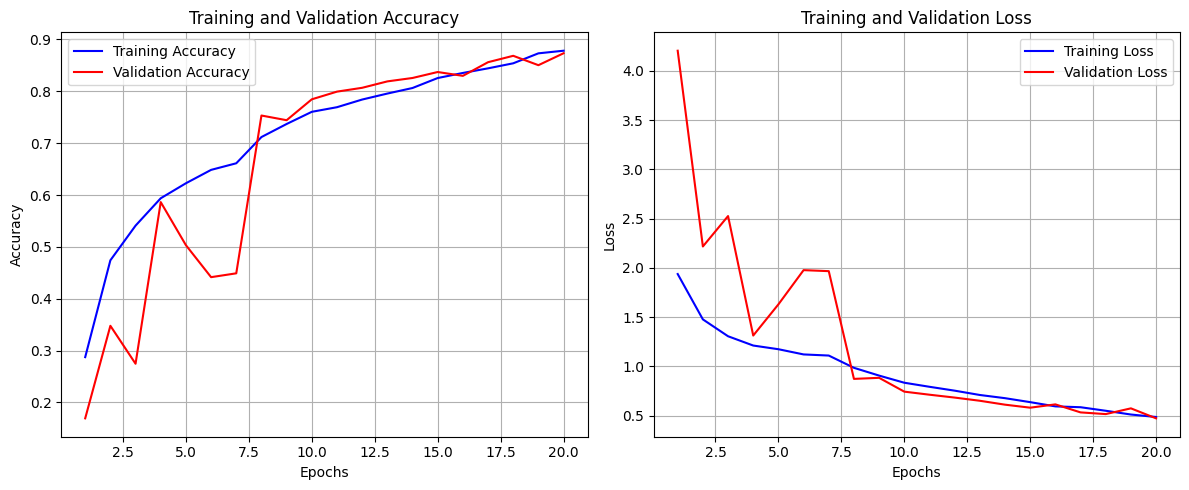

In [19]:
import matplotlib.pyplot as plt
import numpy as np

train_acc = history_3dcnn_rnn.history['accuracy']
val_acc = history_3dcnn_rnn.history['val_accuracy']
train_loss = history_3dcnn_rnn.history['loss']
val_loss = history_3dcnn_rnn.history['val_loss']

epochs = np.arange(1, len(train_acc) + 1)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(epochs, train_acc, 'b-', label='Training Accuracy')
plt.plot(epochs, val_acc, 'r-', label='Validation Accuracy')
plt.title('Training and Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(epochs, train_loss, 'b-', label='Training Loss')
plt.plot(epochs, val_loss, 'r-', label='Validation Loss')
plt.title('Training and Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

In [20]:
import numpy as np
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, classification_report
from tensorflow.keras.utils import to_categorical

# Step 1: Get predictions and true labels from test_generator
y_true = []
y_pred = []

# Iterate through the test_generator
for i in range(len(test_generator)):
    X_batch, y_batch = test_generator[i]
    # Get predicted probabilities and convert to class indices
    pred_batch = model_3dcnn_rnn.predict(X_batch)
    pred_classes = np.argmax(pred_batch, axis=1)
    true_classes = np.argmax(y_batch, axis=1)  # Assuming y_batch is one-hot encoded
    y_true.extend(true_classes)
    y_pred.extend(pred_classes)

y_true = np.array(y_true)
y_pred = np.array(y_pred)

# Step 2: Compute overall accuracy
overall_accuracy = accuracy_score(y_true, y_pred)

# Step 3: Compute precision, recall, and F1-score for each class
precision, recall, f1, _ = precision_recall_fscore_support(y_true, y_pred, average=None)

# Step 4: Map class indices to labels
label_map = {0: 'No gesture', 1: 'Shaking Hand', 2: 'Swiping Up',
             3: 'Thumb Down', 4: 'Thumb Up', 5: 'Zooming Out With Two Fingers'}

# Step 5: Display metrics
print(f"Overall Test Accuracy: {overall_accuracy:.4f}")
print("\nPer-Class Metrics:")
print("-" * 50)
print(f"{'Class':<30} {'Precision':<10} {'Recall':<10} {'F1-Score':<10}")
print("-" * 50)
for i in range(len(label_map)):
    print(f"{label_map[i]:<30} {precision[i]:<10.4f} {recall[i]:<10.4f} {f1[i]:<10.4f}")

# Optional: Detailed classification report
print("\nDetailed Classification Report:")
print(classification_report(y_true, y_pred, target_names=label_map.values()))

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 206ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 197ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 202ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 190ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 221ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 171ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 184ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 172ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 172ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 176ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 170ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 172ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 172ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 183ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 171ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 172ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 190ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 196ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 204ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 196ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 172ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 175ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 174ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 175ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 